# Wood Column / Stud
**NDS 2024 (ASD or LRFD) · NDS Supplement 2024 · ASCE 7-22 load combinations**

Sawn lumber, timber, built-up (multi-ply nailed), glulam, or generic SCL column or wall stud.
Checks the column stability factor CP (NDS 3.7.1), slenderness le/d ≤ 50, combined axial and
biaxial bending (NDS 3.9.2) with end eccentricity and lateral wind on the strong axis, axial
tension with bending (NDS 3.9.1), and plate bearing (NDS 3.10). Includes a stud-wall option for
sheathing weak-axis bracing and repetitive-member factor Cr.

**How to use:** Run the **Engine** cell once, edit the form fields below, and run **Runtime → Run all** (`Ctrl+F9` / `⌘F9`).

> Design aid only. A licensed engineer must verify all inputs and results.

In [1]:
#@title Engine — run this cell first (embedded structcalc library) { display-mode: "form" }
# Unpacks the embedded structcalc library and imports it (no pip install or Drive mount needed).
# Source: structural-calculations (lib/structcalc). Rebuild notebooks with: python build.py
import base64 as _b64, io as _io, os as _os, sys as _sys, tempfile as _tf, zipfile as _zf
_ZIP = (
    "..."
)
_dir = _os.path.join(_tf.gettempdir(), "structcalc_476d0793fd")
if not _os.path.isdir(_os.path.join(_dir, "structcalc")):
    _zf.ZipFile(_io.BytesIO(_b64.b64decode(_ZIP))).extractall(_dir)
for _m in [m for m in _sys.modules if m == "structcalc" or m.startswith("structcalc.")]:
    del _sys.modules[_m]
if _dir not in _sys.path:
    _sys.path.insert(0, _dir)
import structcalc
print(f"structcalc {structcalc.__version__} ready (build 476d0793fd)")

structcalc 0.1.0 ready (build 476d0793fd)


In [2]:
#@title 1. Member and material
size = "2x6"  #@param {type:"string"}
material = "Sawn lumber"  #@param ["Sawn lumber", "Glulam", "LVL 1.9E (generic)", "LVL 2.0E (generic)", "PSL 2.2E (generic)"]
species = "DF-L"  #@param ["DF-L", "Hem-Fir", "SPF", "Southern Pine"]
grade = "Stud"  #@param ["Select Structural", "No.1", "No.2", "No.3", "Stud", "24F-V4", "24F-V8"]
method = "ASD"  #@param ["ASD", "LRFD"]
#@markdown Size examples: `2x6`, `(3)2x6` (built-up, nailed), `6x6` (timber), `6.75x9` (glulam actual in.).

In [3]:
#@title 2. Geometry and bracing
height = 10.0  #@param {type:"number"}
Ke = 1.0  #@param {type:"number"}
weak_bracing = "Braced by sheathing (stud wall)"  #@param ["Same as strong axis", "Braced by sheathing (stud wall)", "Braced at interval"]
weak_interval = 4.0  #@param {type:"number"}
stud_wall = True  #@param {type:"boolean"}
#@markdown Height and interval in **ft**. *Ke*: NDS Appendix G buckling length coefficient (1.0 pinned-pinned). *stud_wall*: applies Cr = 1.15 to Fb.

In [4]:
#@title 3. Loads (service level)
#@markdown Axial loads in **kip** (+ compression, - uplift):
P_D = 0.4  #@param {type:"number"}
P_L = 0.8  #@param {type:"number"}
P_Lr = 0.0  #@param {type:"number"}
P_S = 0.6  #@param {type:"number"}
P_W = 0.0  #@param {type:"number"}
P_E = 0.0  #@param {type:"number"}
ex = 0.0  #@param {type:"number"}
ey = 0.0  #@param {type:"number"}
#@markdown *ex / ey* (in): load eccentricity that bends the weak / strong axis.
wind_psf = 25.0  #@param {type:"number"}
trib_width = 16.0  #@param {type:"number"}
#@markdown *wind_psf*: strength-level (ASCE 7-22) components and cladding pressure on the wall, applied about the strong axis. *trib_width* in in. (stud spacing).

In [5]:
#@title 4. Service conditions and overrides
wet_service = False  #@param {type:"boolean"}
temperature = "T <= 100F"  #@param ["T <= 100F", "100F < T <= 125F", "125F < T <= 150F"]
incised = False  #@param {type:"boolean"}
plate_Fc_perp = 0  #@param {type:"number"}
#@markdown *plate_Fc_perp*: Fc⊥ of the plate (psi), 0 = same as the column species.
#@markdown Reference value overrides (psi, 0 = use table):
Fb = 0  #@param {type:"number"}
Ft = 0  #@param {type:"number"}
Fc = 0  #@param {type:"number"}
Fc_perp = 0  #@param {type:"number"}
E = 0  #@param {type:"number"}
Emin = 0  #@param {type:"number"}

In [6]:
#@title 5. Calculate
from structcalc.calcs import wood_column

out = wood_column.run(
    size=size, material=material, species=species, grade=grade, method=method,
    height=height, Ke=Ke, weak_bracing=weak_bracing, weak_interval=weak_interval,
    P={"D": P_D, "L": P_L, "Lr": P_Lr, "S": P_S, "W": P_W, "E": P_E},
    ex=ex, ey=ey, wind_psf=wind_psf, trib_width=trib_width, stud_wall=stud_wall,
    wet=wet_service, temp=temperature, incised=incised, plate_Fc_perp=plate_Fc_perp,
    override={"Fb": Fb, "Ft": Ft, "Fc": Fc, "Fc_perp": Fc_perp, "E": E, "Emin": Emin},
)
out["report"].show()

Section,2x6 (1.5 x 5.5 in actual),
Material,DF-L Stud,
Height,10,ft
Ke,1,
Weak-axis bracing,Braced by sheathing (stud wall),
Axial load D,0.4,kip
Axial load L,0.8,kip
Axial load S,0.6,kip
Wind pressure (strength level),25,psf
Tributary width,16,in
Stud wall (Cr = 1.15 on Fb),Yes,


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


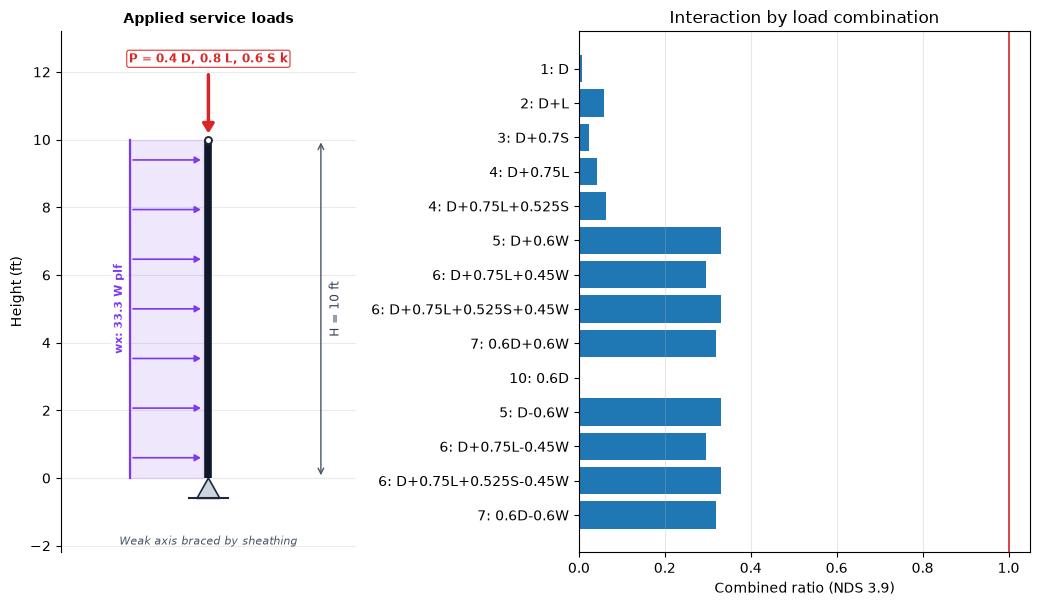

In [7]:
#@title 6. Applied loads and interaction by load combination
fig = wood_column.plot(out)

In [8]:
#@title 7. Save report as HTML (optional)
save_report = False  #@param {type:"boolean"}
if save_report:
    path = out["report"].save_html("wood_column.html")
    print("saved", path)
    try:
        from google.colab import files
        files.download(path)
    except ImportError:
        pass